In [1]:
import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
from ultralytics import YOLO
from roboflow import Roboflow
import math
import os
import glob
import torch
import onnxruntime as ort
from pathlib import Path
import torch
import torch.nn as nn
from torch import optim
from torch.utils.data import Dataset
from torch.utils.data import DataLoader
from torchvision import datasets
from PIL import Image
from torchvision import transforms
from torchvision.transforms import ToTensor
from torch.optim.lr_scheduler import ReduceLROnPlateau
import time

## Import first dataset of non-oriented license plates (for YOLO v11 training)
### Dataset Description:
- Train Images: 21,173
- Validation Images: 2,046
- Test Images: 1,020
- Total Images: 24,239

In [7]:
rf = Roboflow(api_key="uLa3twoEJpTcxKm5TGGq")
project = rf.workspace("roboflow-universe-projects").project("license-plate-recognition-rxg4e")
version = project.version(4)
dataset = version.download("yolov11")

loading Roboflow workspace...
loading Roboflow project...


## Loading the first model (YOLO v11)

In [72]:
# Check and set the device
if torch.cuda.is_available():
    device = "cuda:0"  # Uses the default CUDA GPU
    print(f"Using GPU: {torch.cuda.get_device_name(0)}")
else:
    device = "cpu"
    print("Using CPU.")

# Load a pretrained YOLO model and move it to the GPU
model = YOLO("yolo11n.pt").to(device)

Using GPU: NVIDIA GeForce RTX 3060 Laptop GPU


100%|█████████████████████████████████████████████████████████████████████████████| 5.35M/5.35M [00:00<00:00, 11.3MB/s]


## Training the first model (YOLO v11) on the first dataset to detect license plates

In [5]:
# Train the model using the dataset for 50 epochs on the specified device (GPU)
results = model.train(data="License-Plate-Recognition-4/data.yaml", epochs=50, workers=8, device=device)

New https://pypi.org/project/ultralytics/8.3.100 available  Update with 'pip install -U ultralytics'
Ultralytics 8.3.96  Python-3.9.13 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
engine\trainer: task=detect, mode=train, model=yolo11n.pt, data=License-Plate-Recognition-4/data.yaml, epochs=50, time=None, patience=100, batch=16, imgsz=640, save=True, save_period=-1, cache=False, device=cuda:0, workers=8, project=None, name=train19, exist_ok=False, pretrained=True, optimizer=auto, verbose=True, seed=0, deterministic=True, single_cls=False, rect=False, cos_lr=False, close_mosaic=10, resume=False, amp=True, fraction=1.0, profile=False, freeze=None, multi_scale=False, overlap_mask=True, mask_ratio=4, dropout=0.0, val=True, split=val, save_json=False, save_hybrid=False, conf=None, iou=0.7, max_det=300, half=False, dnn=False, plots=True, source=None, vid_stride=1, stream_buffer=False, visualize=False, augment=False, agnostic_nms=False, classes=None, retina_masks=False

train: Scanning C:\Users\eyadn\OneDrive\Desktop\AUS\Spring 2025\Computer Vision\Project\License-Plate-Recognition-4\tra
val: Scanning C:\Users\eyadn\OneDrive\Desktop\AUS\Spring 2025\Computer Vision\Project\License-Plate-Recognition-4\valid


Plotting labels to runs\detect\train19\labels.jpg... 
optimizer: 'optimizer=auto' found, ignoring 'lr0=0.01' and 'momentum=0.937' and determining best 'optimizer', 'lr0' and 'momentum' automatically... 
optimizer: SGD(lr=0.01, momentum=0.9) with parameter groups 81 weight(decay=0.0), 88 weight(decay=0.0005), 87 bias(decay=0.0)
Image sizes 640 train, 640 val
Using 8 dataloader workers
Logging results to runs\detect\train19
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


       1/50      2.22G       1.22      1.638      1.217         11        640: 100%|██████████| 1324/1324 [04:07<00:00,
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 64/64 [00:17


                   all       2046       2132      0.938      0.901      0.944      0.561

      Epoch    GPU_mem   box_loss   cls_loss   dfl_loss  Instances       Size


...


      50/50      2.71G      0.885     0.3252       1.06          5        640: 100%|██████████| 1324/1324 [03:25<00:00,
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 64/64 [00:14

                   all       2046       2132      0.982      0.966      0.983      0.714

50 epochs completed in 3.477 hours.


Optimizer stripped from runs\detect\train19\weights\last.pt, 5.5MB
Optimizer stripped from runs\detect\train19\weights\best.pt, 5.5MB

Validating runs\detect\train19\weights\best.pt...
Ultralytics 8.3.96  Python-3.9.13 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 64/64 [00:14


                   all       2046       2132      0.982      0.966      0.983      0.714
Speed: 0.2ms preprocess, 1.9ms inference, 0.0ms loss, 1.1ms postprocess per image
Results saved to runs\detect\train19


In [6]:
# Evaluate the model's performance on the validation set
results = model.val(device=device)

Ultralytics 8.3.96  Python-3.9.13 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)
YOLO11n summary (fused): 100 layers, 2,582,347 parameters, 0 gradients, 6.3 GFLOPs


val: Scanning C:\Users\eyadn\OneDrive\Desktop\AUS\Spring 2025\Computer Vision\Project\License-Plate-Recognition-4\valid
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100%|██████████| 128/128 [00:


                   all       2046       2132      0.982      0.966      0.983      0.714
Speed: 0.2ms preprocess, 2.8ms inference, 0.0ms loss, 1.0ms postprocess per image
Results saved to runs\detect\train192


## Exporting the first model (YOLO v11)

In [8]:
# Export the model to ONNX format
success = model.export(format="onnx", device=device)

Ultralytics 8.3.96  Python-3.9.13 torch-2.5.1+cu121 CUDA:0 (NVIDIA GeForce RTX 3060 Laptop GPU, 6144MiB)

PyTorch: starting from 'runs\detect\train19\weights\best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 5, 8400) (5.2 MB)

ONNX: starting export with onnx 1.17.0 opset 19...
ONNX: slimming with onnxslim 0.1.49...
ONNX: export success  1.8s, saved as 'runs\detect\train19\weights\best.onnx' (10.1 MB)

Export complete (1.8s)
Results saved to C:\Users\eyadn\OneDrive\Desktop\AUS\Spring 2025\Computer Vision\Project\runs\detect\train19\weights
Predict:         yolo predict task=detect model=runs\detect\train19\weights\best.onnx imgsz=640  
Validate:        yolo val task=detect model=runs\detect\train19\weights\best.onnx imgsz=640 data=License-Plate-Recognition-4/data.yaml  
Visualize:       https://netron.app


## Creating the second model to predict the rotation of the license plate detected by the first model
### Model Architecture:
- Uses Kaiming initialization
- Uses Convolutional layers
- Uses Batch Normalization
- Uses ReLU activation
- Uses Max Pooling
- Uses Dropout layers

In [70]:
def weights_init_kaiming(m):
    if isinstance(m, nn.Conv2d) or isinstance(m, nn.Linear):
        torch.nn.init.kaiming_normal_(m.weight.data)
        m.bias.data.fill_(0.01)

# Input size: 128x128x3
class AngleRegressionCNN(nn.Module):
    def __init__(self):
        super(AngleRegressionCNN, self).__init__()
        self.network = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm2d(32, affine=False),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # Downsampling by a factor of 2
            
            nn.Conv2d(32, 64, kernel_size=5, stride=1, padding=2),
            nn.BatchNorm2d(64, affine=False),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # Downsampling by a factor of 2

            nn.Conv2d(64, 128, kernel_size=3, stride=1, padding=1),
            nn.BatchNorm2d(128, affine=False),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # Downsampling by a factor of 2
            
            nn.Dropout(0.5),  # Dropout after third block

            nn.Flatten(),  # Flatten the 3D tensor to 1D

            nn.Linear(128 * 16 * 16, 256),  # 32,768 → 256
            nn.BatchNorm1d(256, affine=False),
            nn.ReLU(),

            nn.Linear(256, 1)  # Final regression output
        )        

    def forward(self, x):
        return self.network(x)  # Output shape: (batch_size, 1)

## Created a class to parse the second dataset (oriented license plates) and extract the angle ground truth from the bounding box corners
### Dataset Description:
- Train Images: 979
- Validation Images: 86
- Test Images: 23
- Total Images: 1,088

In [71]:
class LicensePlateAngleDataset(Dataset):
    def __init__(self, image_dir, label_dir, transform=None):
        self.image_paths = glob.glob(os.path.join(image_dir, "*.jpg"))
        self.label_paths = [p.replace("images", "labels").replace(".jpg", ".txt") for p in self.image_paths]
        self.transform = transform
        
        # Remove invalid samples during initialization
        valid_samples = []
        for image_path, label_path in zip(self.image_paths, self.label_paths):
            with open(label_path, 'r') as f:
                line = f.readline().strip()
                parts = list(map(float, line.split()))
                if len(parts) == 9:  # Check for valid label
                    valid_samples.append((image_path, label_path))
        
        # Update the lists to only contain valid samples
        self.image_paths, self.label_paths = zip(*valid_samples) if valid_samples else ([], [])
        
    def __len__(self):
        return len(self.image_paths)

    def _compute_angle(self, corners): # corners format: [x1, y1, x2, y2, x3, y3, x4, y4] normalized
        corners = [(corners[0], corners[1]), 
                   (corners[2],corners[3]),
                   (corners[4],corners[5]),
                   (corners[6],corners[7])]
        # Convert to numpy array for easy computation
        pts = np.array(corners)
        
        # Sum of coordinates (x + y): smallest = top-left, largest = bottom-right
        sums = pts[:, 0] + pts[:, 1]
        # Extract bottom_left corner
        bottom_left = pts[np.argmin(sums)]
        
        # Difference (y - x): smallest = top-right, largest = bottom-left
        diffs = pts[:, 1] - pts[:, 0]
        # Extract bottom_right corner
        bottom_right = pts[np.argmin(diffs)]

        # Calculate the difference in x and y axis
        dy = bottom_right[1] - bottom_left[1]
        dx = bottom_right[0] - bottom_left[0]
        
        angle_rad = math.atan2(dy, dx)  # Angle relative to x-axis
        angle_deg = math.degrees(angle_rad)
    
        return angle_deg
    
    def __getitem__(self, idx):
        img = Image.open(self.image_paths[idx]).convert("RGB")

        with open(self.label_paths[idx], 'r') as f:
            line = f.readline().strip()
            parts = list(map(float, line.split()))
        
            if len(parts) != 9:  # Skip invalid labels
                print(f"Skipping invalid label: {self.label_paths[idx]}")
                return None  # Or handle the case when a valid image-label pair isn't found
        
            corners = parts[1:]
        
        angle = self._compute_angle(corners)
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor([angle], dtype=torch.float32)



## Training and validation function for the second model

In [86]:
def train_and_validate(model, trainloader, valloader, criteria, optimizer, scheduler=None, tolerance=5.0, epochs=100):
    start_time = time.time()

    for epoch in range(epochs):
        train_loss = 0.0
        model.train()  # set the model to training mode
        
        # Training loop
        train_loss = 0
        train_accuracy = 0
        total_train = 0
        correct_train = 0
        for i, data in enumerate(trainloader):
            inputs, labels = data
            inputs = inputs.to(device)
            labels = labels.to(device)
            
            optimizer.zero_grad()  # zero the gradients
            
            outputs = model(inputs)  # forward pass
            
            loss = criteria(outputs, labels)  # calculate loss
            loss.backward()  # backpropagation
            
            optimizer.step()  # optimize
            
            train_loss += loss.item()  # accumulate training loss
            
            # Track training accuracy
            correct_train += (torch.abs(outputs.squeeze() - labels) < tolerance).sum().item()
            total_train += labels.size(0)
            
        train_accuracy = correct_train / total_train  # calculate training accuracy
        
        # Validation loop after each epoch
        with torch.no_grad():  # no gradients needed for validation
            val_loss = 0.0
            val_accuracy = 0.0
            correct = 0
            total = 0
            
            for data in valloader:  # use valloader for validation
                inputs, labels = data
                inputs = inputs.to(device)
                labels = labels.to(device)
                
                outputs = model(inputs)
                loss = criteria(outputs, labels)
                val_loss += loss.item()
                
                # Calculate accuracy
                correct += (torch.abs(outputs.squeeze() - labels) < tolerance).sum().item()
                total += labels.size(0)
            
        avg_val_loss = val_loss / len(valloader)
        val_accuracy = correct / total  # calculate validation accuracy
        # scheduler.step(val_loss)
        
        # Print the loss and accuracy for both training and validation
        if (epoch + 1) % 50 == 0:
            print(f'Epoch [{epoch+1}/{epochs}], '
                  f'train loss: {train_loss/len(trainloader):.4f}, '
                  f'val loss: {val_loss/len(valloader):.4f}, '
                  f'train accuracy: {train_accuracy:.4f}, '
                  f'val accuracy: {val_accuracy:.4f}')
            
        # Store losses and accuracies for plotting
        train_history.append(train_loss/len(trainloader))
        val_history.append(val_loss/len(valloader))
        train_accuracies.append(train_accuracy)
        val_accuracies.append(val_accuracy)

        if epoch+1 == 100:
            torch.save(model, '100_angle_cnn_model.pth')
            torch.save(model.state_dict(), '100_angle_cnn_weights.pth')
        if epoch+1 == 500:
            torch.save(model, '500_angle_cnn_model.pth')
            torch.save(model.state_dict(), '500_angle_cnn_weights.pth')
        if epoch+1 == 1000:
            torch.save(model, '1k_angle_cnn_model.pth')
            torch.save(model.state_dict(), '1k_angle_cnn_weights.pth')
        if epoch+1 == 1500:
            torch.save(model, '1.5k_angle_cnn_model.pth')
            torch.save(model.state_dict(), '1.5k_angle_cnn_weights.pth')
        if epoch+1 == 2000:
            torch.save(model, '2k_angle_cnn_model.pth')
            torch.save(model.state_dict(), '2k_angle_cnn_weights.pth')
        if epoch+1 == 2500:
            torch.save(model, '2.5k_angle_cnn_model.pth')
            torch.save(model.state_dict(), '2.5k_angle_cnn_weights.pth')
        if epoch+1 == 3000:
            torch.save(model, '3k_angle_cnn_model.pth')
            torch.save(model.state_dict(), '3k_angle_cnn_weights.pth')
        if epoch+1 == 3500:
            torch.save(model, '3.5k_angle_cnn_model.pth')
            torch.save(model.state_dict(), '3.5k_angle_cnn_weights.pth')
        if epoch+1 == 4000:
            torch.save(model, '4k_angle_cnn_model.pth')
            torch.save(model.state_dict(), '4k_angle_cnn_weights.pth')
        if epoch+1 == 4500:
            torch.save(model, '4.5k_angle_cnn_model.pth')
            torch.save(model.state_dict(), '4.5k_angle_cnn_weights.pth')
        # if epoch == 5000:
        #     torch.save(model, '5k_angle_cnn_model.pth')
        #     torch.save(model.state_dict(), '5k_angle_cnn_weights.pth')
        # if epoch == 7500:
        #     torch.save(model, '7.5k_angle_cnn_model.pth')
        #     torch.save(model.state_dict(), '7.5k_angle_cnn_weights.pth')
    
    end_time = time.time()
    total_time = end_time - start_time
    print(f"\nTraining completed in {total_time:.2f} seconds ({total_time/60:.2f} minutes)")

## Loading the second dataset (oriented license plates) for training and validation
### Techniques used:
- Data Augmentation
- MSE Loss Function
- Adam Optimizer
- 5,000 epochs (interrupted at 3,000 epochs due to time constraint)

In [87]:
transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor(),
])

# Data Augmentation
train_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.RandomRotation(10), 
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])

trainset = LicensePlateAngleDataset(image_dir="License-Plates-OBB-1/train/images", label_dir="License-Plates-OBB-1/train/labels", transform=train_transform)
valset = LicensePlateAngleDataset(image_dir="License-Plates-OBB-1/valid/images", label_dir="License-Plates-OBB-1/valid/labels", transform=transform)
testset = LicensePlateAngleDataset(image_dir="License-Plates-OBB-1/test/images", label_dir="License-Plates-OBB-1/test/labels", transform=transform)

batchsize = 64
trainloader = DataLoader(trainset, batch_size=batchsize, shuffle=True)
testloader = DataLoader(testset, batch_size=batchsize, shuffle=False)
valloader = DataLoader(valset, batch_size=batchsize, shuffle=False)

In [91]:
from torch.optim.lr_scheduler import ReduceLROnPlateau
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

model = AngleRegressionCNN()
model.to(device)
model.apply(weights_init_kaiming)
print(device)
print(model)

# L2 Regularization
# optimizer = optim.SGD(
#     model.parameters(),
#     lr=0.0001,
#     momentum=0.9,
#     weight_decay=1e-4
# )
criteria = nn.MSELoss()
# optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=0.0001)
optimizer = optim.Adam(model.parameters(), lr=0.00001) #,weight_decay=0.000001)
# optimizer = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=1e-2)
# scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.5, patience=5)
# scheduler = StepLR(optimizer, step_size=5, gamma=0.5)
scheduler = None
train_history = []
val_history = []
train_accuracies = []
val_accuracies = []

cuda
AngleRegressionCNN(
  (network): Sequential(
    (0): Conv2d(3, 32, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=False, track_running_stats=True)
    (2): ReLU()
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(5, 5), stride=(1, 1), padding=(2, 2))
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=False, track_running_stats=True)
    (6): ReLU()
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=False, track_running_stats=True)
    (10): ReLU()
    (11): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (12): Dropout(p=0.5, inplace=False)
    (13): Flatten(start_dim=1, end_dim=-1)
    (14): Linear(in_features=32768, out_features=256, bias=True)
    

In [92]:
train_and_validate(model, trainloader, valloader, criteria, optimizer, scheduler, epochs=5000)
torch.save(model, '5k_angle_cnn_model.pth')
torch.save(model.state_dict(), '5k_angle_cnn_weights.pth')

Epoch [50/5000], train loss: 11.6956, val loss: 11.5446, train accuracy: 48.8151, val accuracy: 44.3038
Epoch [100/5000], train loss: 8.2577, val loss: 11.9555, train accuracy: 47.8787, val accuracy: 43.2152
Epoch [150/5000], train loss: 4.9861, val loss: 11.7252, train accuracy: 46.8163, val accuracy: 42.6329
Epoch [200/5000], train loss: 3.8396, val loss: 12.9991, train accuracy: 45.9517, val accuracy: 42.0506
Epoch [250/5000], train loss: 3.2282, val loss: 15.4933, train accuracy: 45.1060, val accuracy: 42.3797
Epoch [300/5000], train loss: 2.6428, val loss: 14.2648, train accuracy: 45.0742, val accuracy: 41.0380
Epoch [350/5000], train loss: 2.4082, val loss: 14.2400, train accuracy: 44.9788, val accuracy: 41.0000
Epoch [400/5000], train loss: 2.3218, val loss: 16.4518, train accuracy: 44.7420, val accuracy: 41.1139
Epoch [450/5000], train loss: 2.0676, val loss: 16.2769, train accuracy: 44.4688, val accuracy: 40.8608
Epoch [500/5000], train loss: 2.1130, val loss: 16.4809, train a

KeyboardInterrupt: 

## Save best angle model (interrupted at 3,000 epochs)

In [99]:
torch.save(model, 'best_angle_cnn_model.pth')
torch.save(model.state_dict(), 'best_angle_cnn_weights.pth')

## Plotting training and validation loss and accuracy

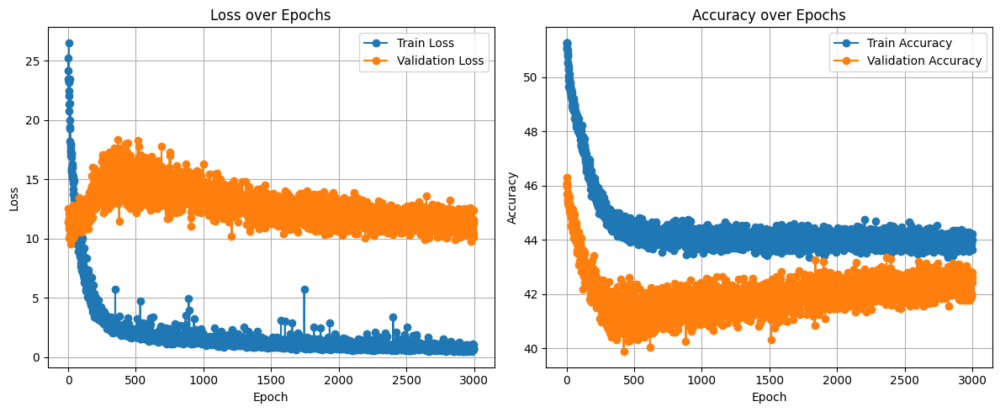

In [93]:
# Plot the loss and accuracy for train and validation
plt.figure(figsize=(12, 5))

# Plot Loss
plt.subplot(1, 2, 1)
plt.plot(train_history, label='Train Loss', marker='o')
plt.plot(val_history, label='Validation Loss', marker='o')
plt.title('Loss over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

# Plot Accuracy
plt.subplot(1, 2, 2)
plt.plot(train_accuracies, label='Train Accuracy', marker='o')
plt.plot(val_accuracies, label='Validation Accuracy', marker='o')
plt.title('Accuracy over Epochs')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

## Testing the second model (very small testing set)

In [98]:
# Testing the model after training is done
model.eval()  # set the model to evaluation mode for testing
test_loss = 0.0
test_accuracy = 0.0
correct = 0
total = 0

with torch.no_grad():  # no gradients needed for testing
    for data in testloader:  # use testloader for testing
        inputs, labels = data
        inputs = inputs.to(device)
        labels = labels.to(device)
        
        outputs = model(inputs)
        loss = criteria(outputs, labels)
        test_loss += loss.item()
        
        # Accuracy: prediction is correct if within 1 degree of ground truth
        diff = torch.abs(outputs - labels)
        correct += (diff < 5.0).sum().item()
        total += labels.size(0)

test_accuracy = correct / total  # calculate test accuracy

# Print test results
print(f'Test Loss: {test_loss/len(testloader):.4f}')
print(f'Test Accuracy (within ±5°): {test_accuracy*100:.4f}%')


Test Loss: 20.1810
Test Accuracy (within ±5°): 72.2222%


## Project Demo

In [100]:
def get_upright_plate(plate_img, top_left, width, height):
    width = math.ceil(width)
    height = math.ceil(height)
    
    plate_corners = np.array([
        [top_left[0], top_left[1]], # top-left
        [top_left[0] + width, top_left[1]], # top-right
        [top_left[0], top_left[1] + height], # bottom-left
        [top_left[0] + width, top_left[1] + height] # bottom-right
    ], np.float32)
 
    output_pts = np.array([[0,0],[width - 1, 0], [0, height - 1], [width - 1, height - 1]], np.float32)
    
    H = cv.getPerspectiveTransform(plate_corners, output_pts)
    
    upright_plate = cv.warpPerspective(plate_img, H, dsize=(width, height)) # Get the upright plate

    return cv.cvtColor(upright_plate, cv.COLOR_BGR2RGB)

In [101]:
def xywh_to_xyxy(box):
    x_center, y_center, w, h = box
    x1 = x_center - w / 2
    y1 = y_center - h / 2
    x2 = x_center + w / 2
    y2 = y_center + h / 2
    return [x1, y1, x2, y2]

In [102]:
# --- Helper: get rotated corners from bbox + angle ---
def get_rotated_corners(x1, y1, x2, y2, angle_deg):
    cx = (x1 + x2) / 2
    cy = (y1 + y2) / 2
    w = x2 - x1
    h = y2 - y1

    # Define the 4 corners relative to the center
    corners = np.array([
        [-w/2, -h/2],  # top-left
        [ w/2, -h/2],  # top-right
        [ w/2,  h/2],  # bottom-right
        [-w/2,  h/2],  # bottom-left
    ])

    # Rotation matrix
    theta = np.deg2rad(angle_deg)
    rotation_matrix = np.array([
        [np.cos(theta), -np.sin(theta)],
        [np.sin(theta),  np.cos(theta)],
    ])

    # Rotate and shift back to center
    rotated_corners = np.dot(corners, rotation_matrix.T) + np.array([cx, cy])
    return rotated_corners


In [103]:
def process_detections(output_data, conf_threshold=0.1):
    detections = output_data[0].T  # Shape (8400, 5): (x, y, w, h, conf)
    results = []
    for det in detections:
        x, y, w, h, conf = det
        if conf > conf_threshold:
            results.append((x, y, w, h, conf))
    return results

In [104]:
# Apply Non-Maximum Suppression (NMS)
def apply_nms(detections, iou_threshold=0):
    if len(detections) == 0:
        return []

    # Convert detections to [x1, y1, x2, y2] format
    boxes = []
    confidences = []
    for (x, y, w, h, conf) in detections:
        x1 = (x - w / 2)
        y1 = (y - h / 2)
        x2 = (x + w / 2)
        y2 = (y + h / 2)
        boxes.append([x1, y1, x2, y2])
        confidences.append(conf)
    
    # Convert to numpy arrays for easier manipulation
    boxes = np.array(boxes)
    confidences = np.array(confidences)

    # Perform NMS
    indices = cv.dnn.NMSBoxes(boxes.tolist(), confidences.tolist(), score_threshold=0.1, nms_threshold=iou_threshold)
    
    # Extract the final detections
    final_detections = []
    for i in indices.flatten():
        final_detections.append(detections[i])
    return final_detections

In [127]:
# --- Load YOLOv11 ONNX Model ---
onnx_model_path = "runs/detect/train19/weights/best.onnx"
onnx_session = ort.InferenceSession(onnx_model_path, providers=["CPUExecutionProvider"])

# --- Load the angle prediction model ---
angle_model = torch.load('best_angle_cnn_model.pth')
angle_model.eval()
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
angle_model.to(device)

# --- Preprocessing for angle model ---
angle_transform = transforms.Compose([
    transforms.Resize((128, 128)),
    transforms.ToTensor()
])

# --- Inference Function ---
def process_image(image_path):
    # Load and prepare image
    img = cv.imread(image_path)
    img_rgb = cv.cvtColor(img, cv.COLOR_BGR2RGB)
    orig_h, orig_w = img.shape[:2]
    resized_img = cv.resize(img_rgb, (640, 640))
    img_input = resized_img.astype(np.float32).transpose(2, 0, 1) / 255.0
    img_input = np.expand_dims(img_input, axis=0)

    # Show original image
    plt.figure(figsize=(6, 6))
    plt.imshow(img_rgb)
    plt.title("Original Image")
    plt.axis('off')
    plt.show()

    # Run YOLOv11 ONNX model
    detections = onnx_session.run(None, {"images": img_input})[0]
    detections = process_detections(detections, 0.25)
    detections = apply_nms(detections)
    if len(detections) == 0:
        print(f"No detections in {image_path}")
        return None, None, None

    upright_plates = []
    angles = []
    corners_list = []

    for x, y, w, h, conf in detections:
        scale_x = orig_w / 640
        scale_y = orig_h / 640
        x *= scale_x
        y *= scale_y
        w *= scale_x
        h *= scale_y

        x1, y1, x2, y2 = xywh_to_xyxy([x, y, w, h])
        crop = img_rgb[int(y1):int(y2), int(x1):int(x2)]

        if crop.size == 0:
            continue  # skip invalid crop

        plate_img = Image.fromarray(crop)
        input_tensor = angle_transform(plate_img).unsqueeze(0).to(device)
        
        with torch.no_grad():
            angle_deg = angle_model(input_tensor).item()
        
        corners = get_rotated_corners(x1, y1, x2, y2, angle_deg)
        sums = corners.sum(axis=1)
        top_left = corners[np.argmin(sums)]
        width = np.linalg.norm(corners[1] - corners[0])
        height = np.linalg.norm(corners[3] - corners[0])
        upright = get_upright_plate(img_rgb, top_left, width, height)

        upright_plates.append(upright)
        angles.append(angle_deg)
        corners_list.append(corners)

    return upright_plates, angles, corners_list


Processing 0002a5b67e5f0909_jpg.rf.07ca41e79eb878b14032f650f34d0967.jpg


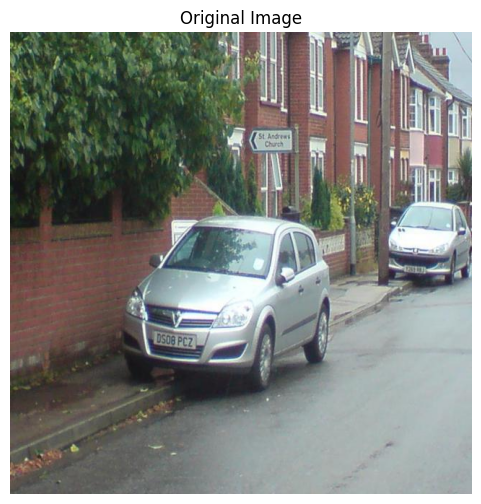

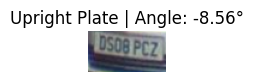

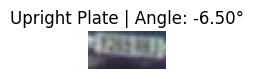

Processing 000812dcf304a8e7_jpg.rf.559f904bc045f68ee947796a1b561d8f.jpg


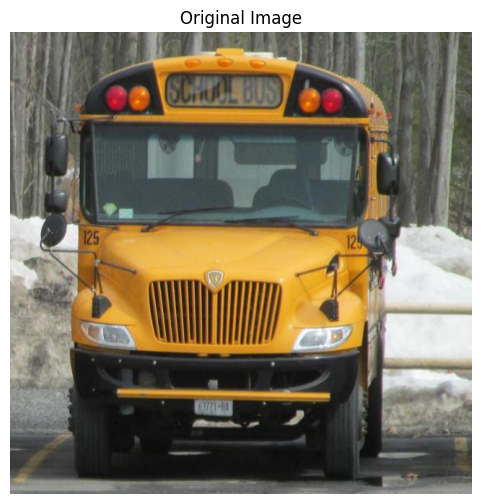

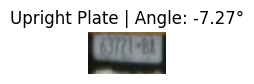

Processing 0010f4c10f7ab07e_jpg.rf.92344aa620e23aacc490273e32343595.jpg


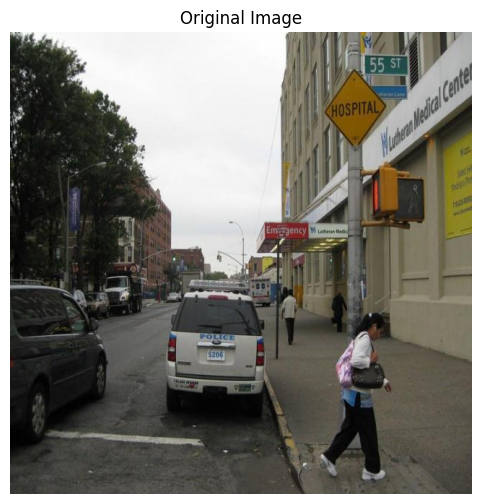

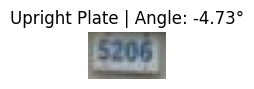

Processing 001cdd25e148cd36_jpg.rf.eca53e55e3cf5986bcfd95bc277b6438.jpg


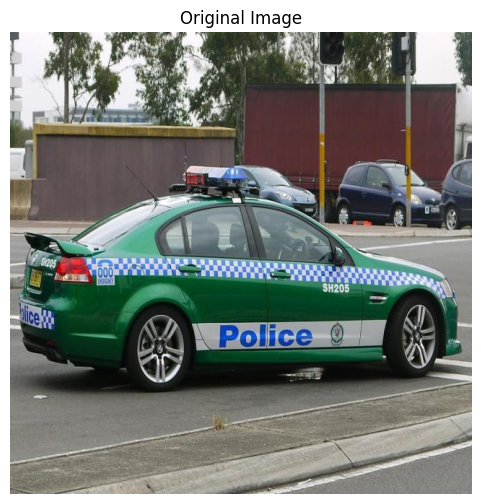

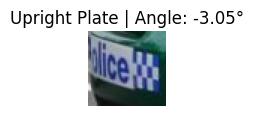

Processing 002519f868563098_jpg.rf.b9450b9265c92d8d3bd96bdfeff635e5.jpg


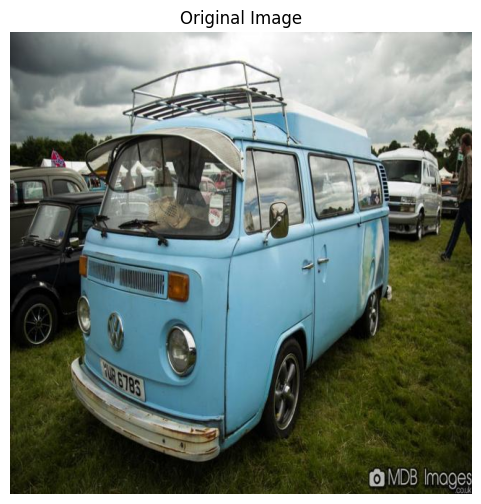

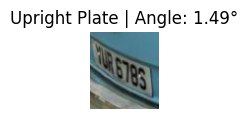

Processing 0026c246d5c33bea_jpg.rf.782def291f7881f554c7a8bd17b9ff13.jpg


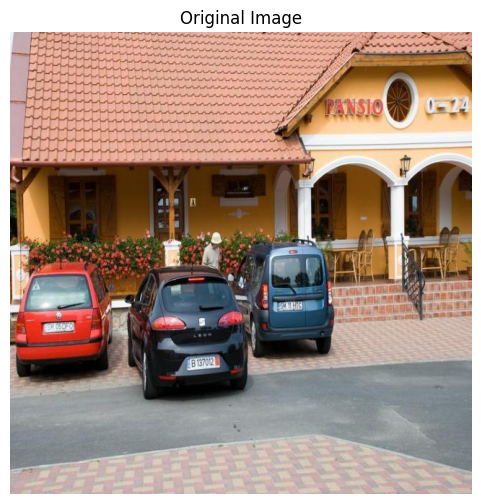

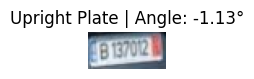

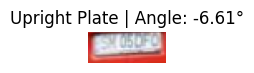

Processing 002901d9d194c4fb_jpg.rf.292313a88fa94fe76a51739acc95b5ab.jpg


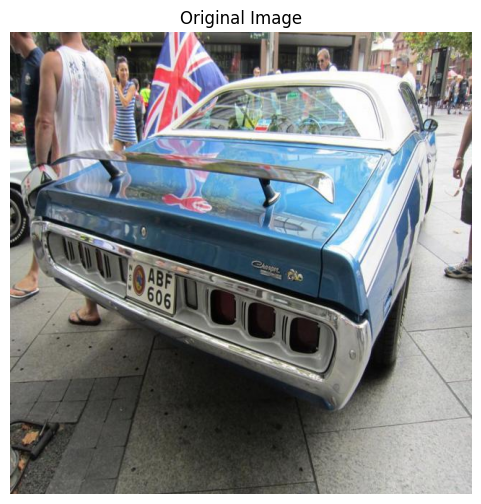

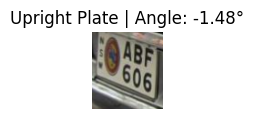

Processing 002d099996f3f443_jpg.rf.d219313b73c017c10dbe786ec8743b03.jpg


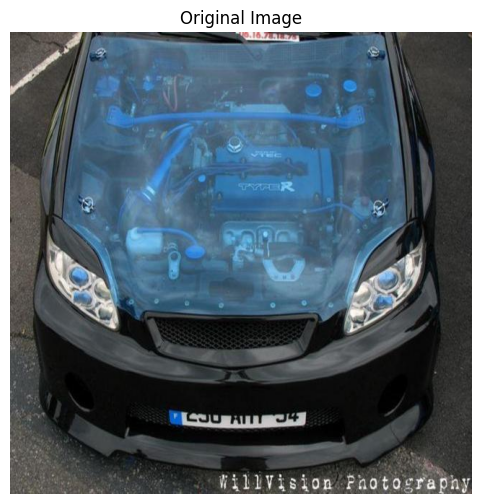

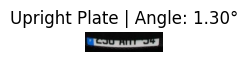

Processing 0039ac4bfb8bd69d_jpg.rf.8ed0bdac228b8da2b163f8f4ec3ee12d.jpg


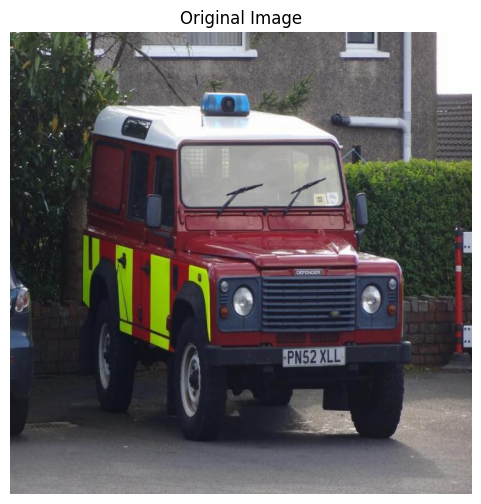

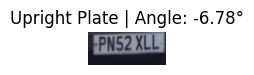

Processing 005e1faed531ae7e_jpg.rf.641f4e0212615f9577971c7996785998.jpg


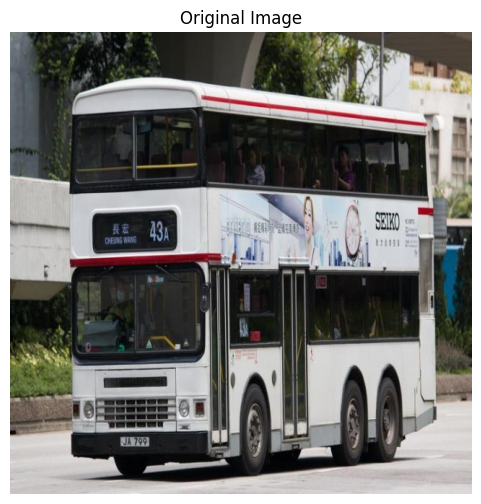

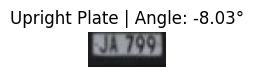

Processing 0063e41b53567829_jpg.rf.93b2fcf6eeae4c619b1dd665e713f092.jpg


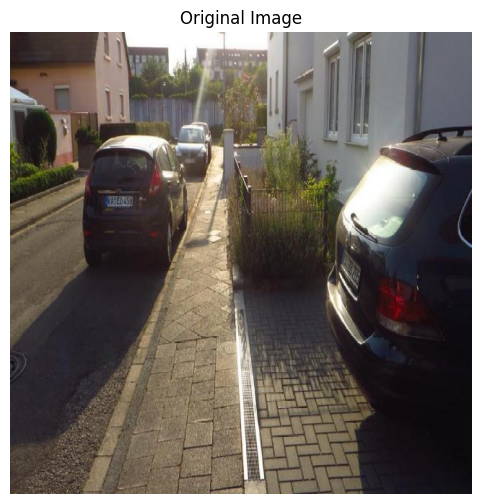

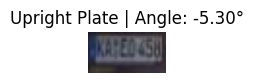

Processing 006a2f13b5b16c64_jpg.rf.e820f8b40c945dad83266d7de46547ed.jpg


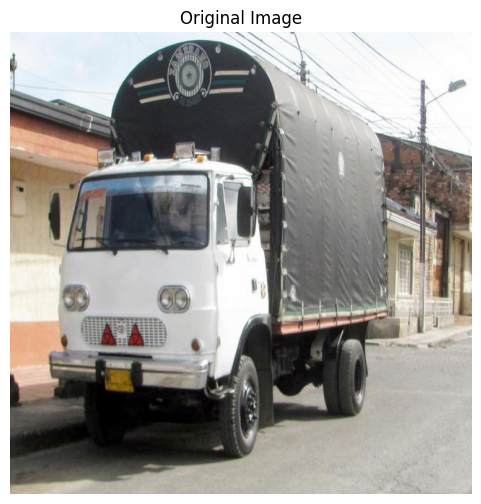

No detections in License-Plate-Recognition-4\test\images\006a2f13b5b16c64_jpg.rf.e820f8b40c945dad83266d7de46547ed.jpg
Processing 00777823afff31f7_jpg.rf.01bd33791b0d7a14ff785477bade66bc.jpg


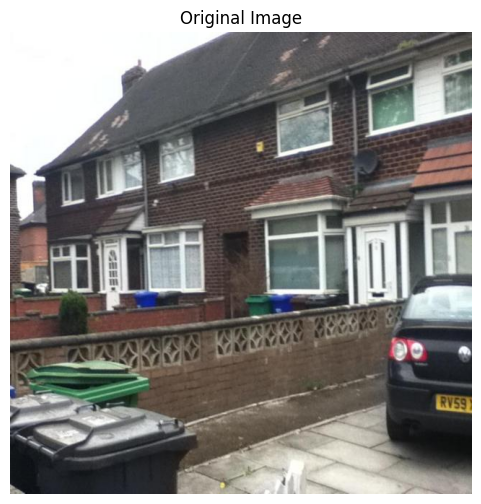

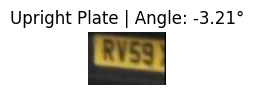

Processing 0088be963439e57d_jpg.rf.86aac5ac6fc2739dec461915633d636c.jpg


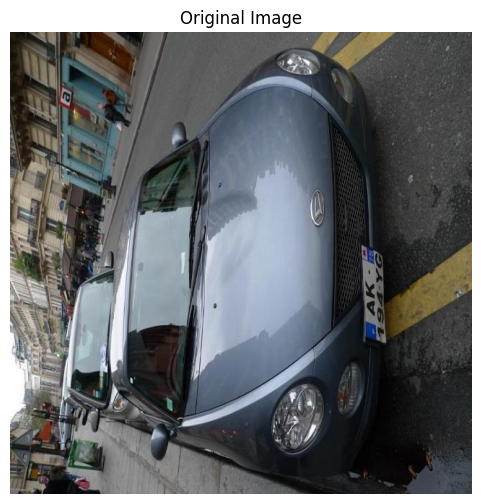

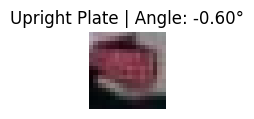

Processing 008e36a5a0623445_jpg.rf.c0df6282d2fe4484c4c6de82acbb2ab5.jpg


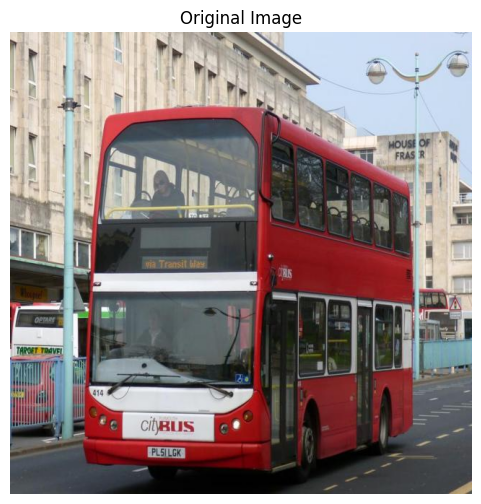

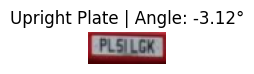

Processing 00a7d31c6cc6b7f3_jpg.rf.2707e63f5c51f113de704441ea210a65.jpg


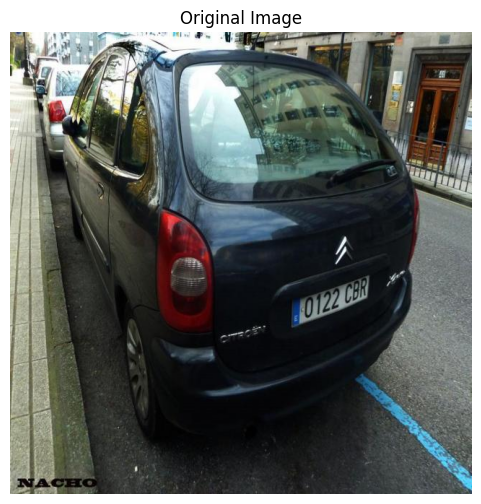

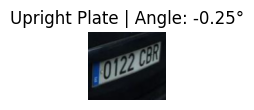

Processing 00c82d64185293a7_jpg.rf.d927fad96de9f7b21d10616035d07517.jpg


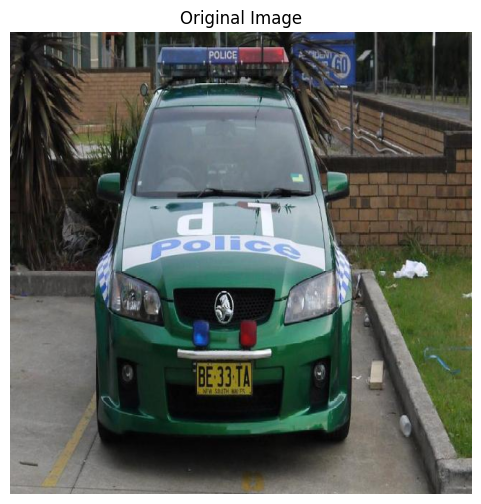

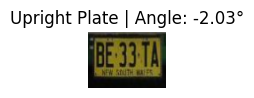

Processing 00d9db3d2c186504_jpg.rf.dbef0ff244b8391e10e46b8e378da86f.jpg


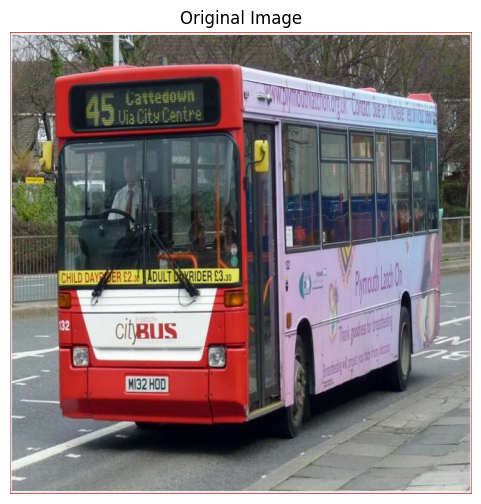

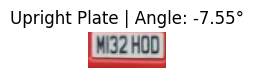

Processing 00e481ea1a520175_jpg.rf.0818727629d317c7c097b6d662d0c6f9.jpg


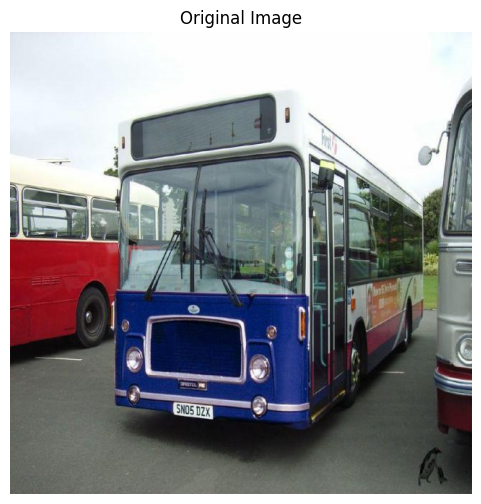

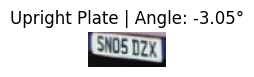

Processing 00e4cd60e84c0463_jpg.rf.c14f84986360a80ea34f8ae1d2fe822e.jpg


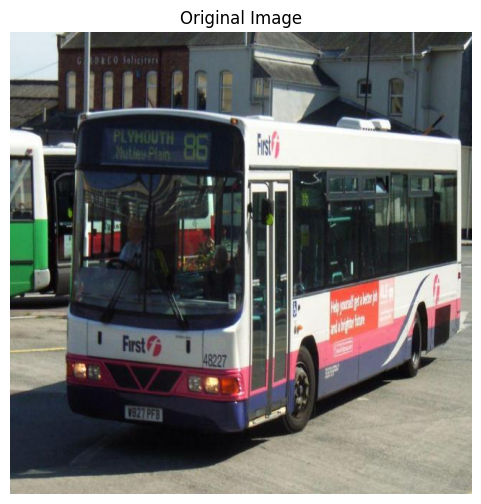

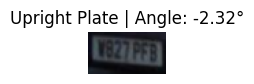

Processing 00e8e5e79255536f_jpg.rf.07cf07851218145d72e84778d79a2999.jpg


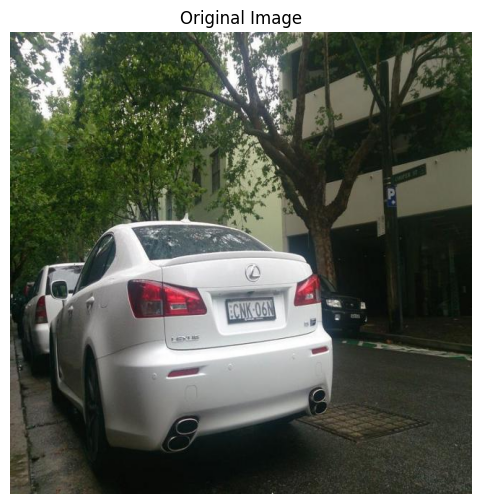

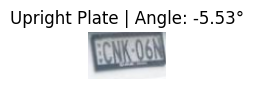

Processing 0123f836ce94678a_jpg.rf.c2c72263ce513bd9a8b56d2a162e1950.jpg


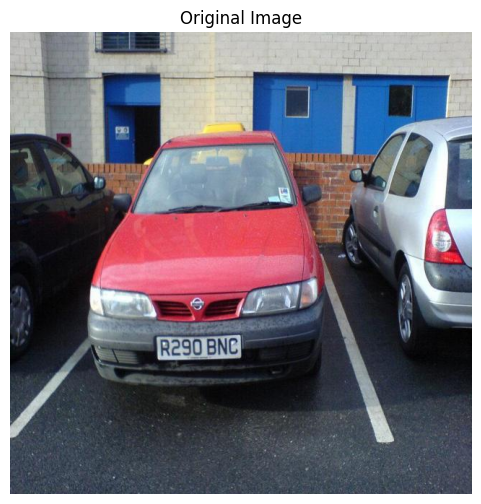

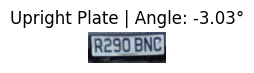

Processing 01984a985e4bf80f_jpg.rf.731119098337a60b6f8f401d1367e815.jpg


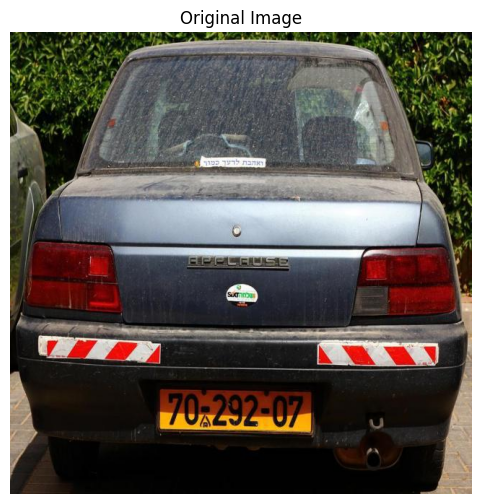

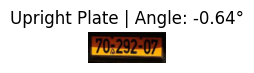

Processing 021d0fd9b41f8d4b_jpg.rf.6b572e11e5d466dfa06aa0fd5fef7857.jpg


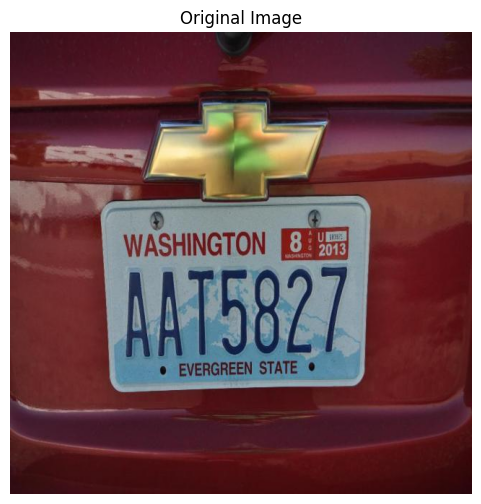

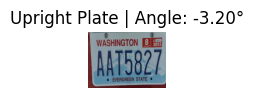

Processing 024a77ccdb9410b1_jpg.rf.aa59b8d8bfde223df4989fac8b578a74.jpg


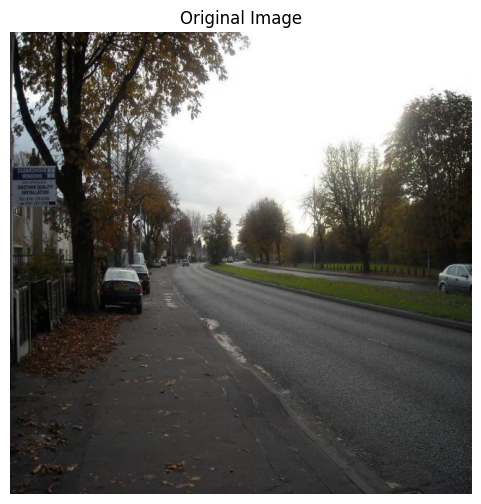

No detections in License-Plate-Recognition-4\test\images\024a77ccdb9410b1_jpg.rf.aa59b8d8bfde223df4989fac8b578a74.jpg
Processing 0269b68e1093b0be_jpg.rf.29fd59c72a78dd9e2406c280d07503d3.jpg


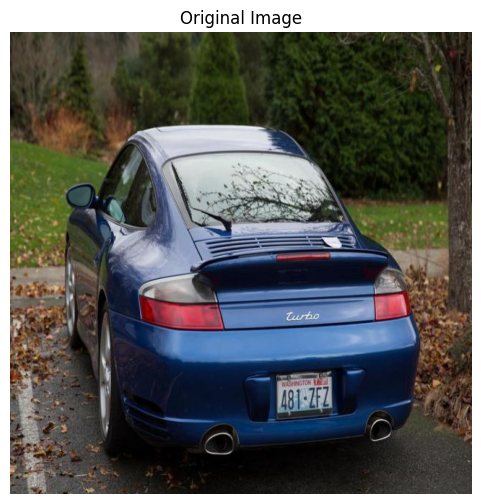

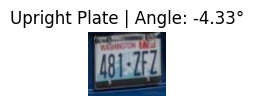

Processing 02a3ba4c3886fe9a_jpg.rf.3eed71c4a4d26606beff7edb40836fdd.jpg


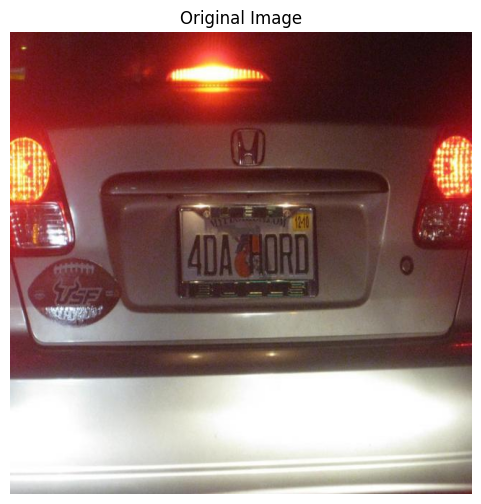

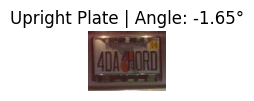

Processing 02fee967ac39acf0_jpg.rf.98feea50ab065f1884128ffd14beefe1.jpg


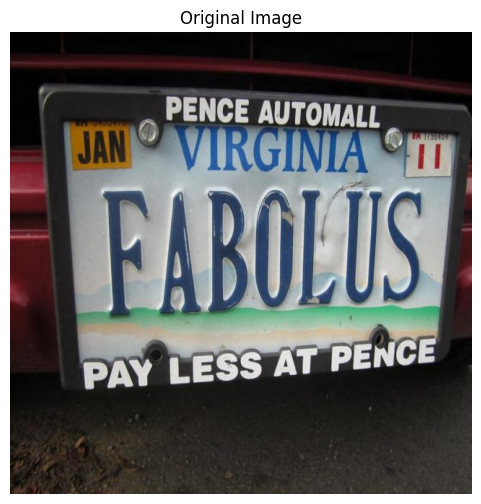

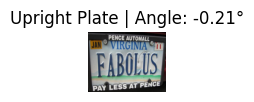

Processing 11-Guerrero-2BPlaca-2Bcapacidades-2Bdiferentes-2B99-GAA-2BFranja-2Babajo_jpg.rf.950a857dba98a7fda4f1c04e8c73488f.jpg


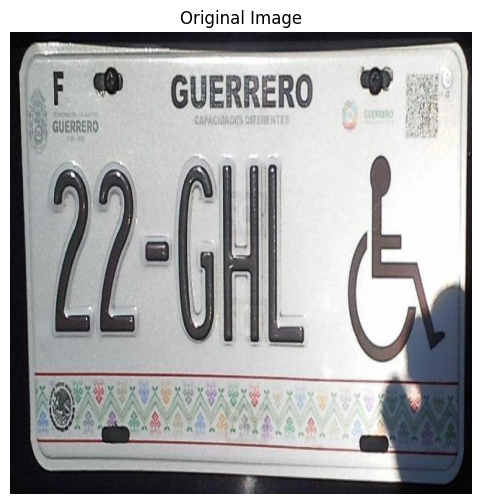

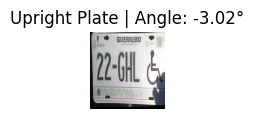

Processing 1649292507297_jpg.rf.596999ed480c8e7dd20b2dcd093f74b7.jpg


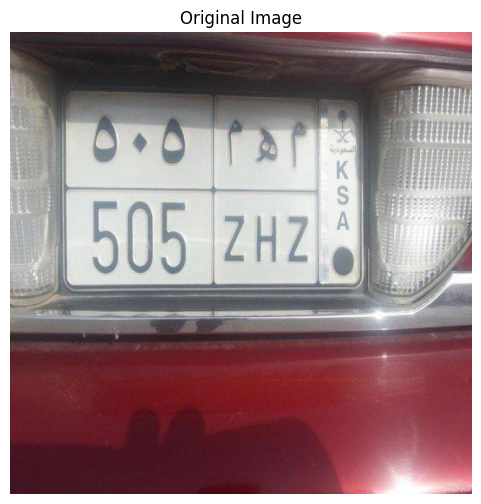

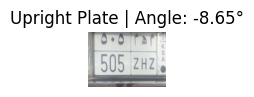

Processing 1649292507302_jpg.rf.9f046504b75978c601bcb5095a0b7c63.jpg


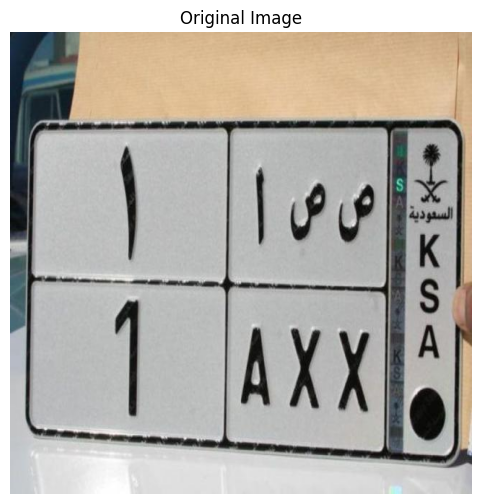

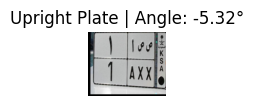

Processing 1649292507305_jpeg_jpg.rf.cff837a4b87d0e7b667a785d88ec3401.jpg


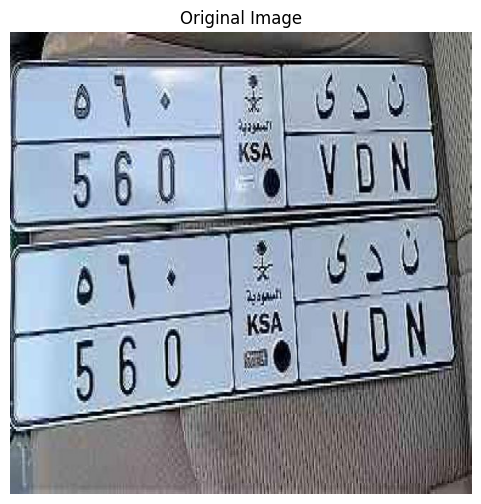

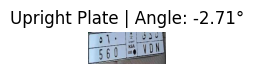

In [130]:
images_path = "License-Plate-Recognition-4/test/images"
num_test_imgs = 30
i = 0
# Process all images in the test folder
for image_file in Path(images_path).glob('*.*'):
    if i == num_test_imgs:
        break
    if image_file.suffix.lower() in ['.jpg', '.png', '.jpeg']:
        print(f"Processing {image_file.name}")
        upright_plates, angles, corners_list = process_image(image_file)

        if upright_plates is None:
            continue

        for plate, angle in zip(upright_plates, angles):
            plt.figure(figsize=(1, 1))
            plt.imshow(cv.cvtColor(plate, cv.COLOR_BGR2RGB))
            plt.title(f"Upright Plate | Angle: {angle:.2f}°")
            plt.axis('off')
            plt.show()
        i += 1
